# Phase 1: Data Exploration and analysis

**A note on authentication.** As of October 2026, F1 requires an F1TV account to access its public API so in order to use FastF1 you would need to create and sign in to your account. (No paid subscription required)

```
source .venv/bin/activate
python -m fastf1 auth f1tv --authenticate
```

This will prompt for your F1TV email and password directly in the terminal and store a login token locally. The token lasts about four days so this needs repeating periodically.

Ignore any error or warning logs when you run the notebook

In [1]:
import fastf1
import pandas as pd
import matplotlib.pyplot as plt

# Local cache so a session never has to be downloaded twice.
fastf1.Cache.enable_cache("../data/fastf1_cache")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

/Users/frank/Computer Science/f1-strategy-optimiser/.venv/lib/python3.13/site-packages/fastf1/req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "


## How many races are in this season 2026

FastF1's event schedule gives one row per race weekend, including pre-season testing as round 0.

In [2]:
schedule = fastf1.get_event_schedule(2026)
print("Number of races in 2026:", (schedule["RoundNumber"] > 0).sum())
schedule[["RoundNumber", "EventName", "Location", "EventDate"]]

Number of races in 2026: 23


,RoundNumber,EventName,Location,EventDate
0,0,Pre-Season Testing,Bahrain,2026-02-13
1,0,Pre-Season Testing,Bahrain,2026-02-20
2,1,Australian Grand Prix,Melbourne,2026-03-08
3,2,Chinese Grand Prix,Shanghai,2026-03-15
4,3,Japanese Grand Prix,Suzuka,2026-03-29
5,4,Miami Grand Prix,Miami Gardens,2026-05-03
6,5,Canadian Grand Prix,Montréal,2026-05-24
7,6,Monaco Grand Prix,Monte Carlo,2026-06-07
8,7,Barcelona Grand Prix,Barcelona,2026-06-14
9,8,Austrian Grand Prix,Spielberg,2026-06-28


## How many races FastF1 has in total, across every season

In [3]:
season_race_counts = {}
for year in range(2018, 2027):
    sched = fastf1.get_event_schedule(year)
    season_race_counts[year] = int((sched["RoundNumber"] > 0).sum())

counts_df = pd.DataFrame(season_race_counts.items(), columns=["Season", "Races"]).set_index("Season")
print(counts_df)
print("Total races across all seasons FastF1 covers:", counts_df["Races"].sum())

        Races
Season       
2018       21
2019       21
2020       17
2021       22
2022       22
2023       22
2024       24
2025       24
2026       23
Total races across all seasons FastF1 covers: 196


## How many sprint races F1 has hosted

F1 introduced the sprint race (a shortened race about 30 laps or less) from 2021 onwards.
The current format of a sprint weekend is 
Friday: 1 Free practice session, Sprint Qualifying,
Saturday: Sprint Race, Qualifying,
Sunday: Race

In [4]:
sprint_counts = {}
for year in range(2018, 2027):
    sched = fastf1.get_event_schedule(year)
    sprint_counts[year] = int(sched["EventFormat"].str.contains("sprint", na=False).sum())

sprint_df = pd.DataFrame(sprint_counts.items(), columns=["Season", "Sprints"]).set_index("Season")
print(sprint_df)
print("Total sprint weekends F1 has hosted:", sprint_df["Sprints"].sum())

        Sprints
Season         
2018          0
2019          0
2020          0
2021          3
2022          3
2023          6
2024          6
2025          6
2026          6
Total sprint weekends F1 has hosted: 30


## Who is the GOAT in the FastF1 era

Lets see who has the most race wins from 2018 to now

In [5]:
from collections import Counter

win_counts = Counter()
today = pd.Timestamp.now()

for year in range(2018, 2027):
    sched = fastf1.get_event_schedule(year)
    rounds = sched[(sched["RoundNumber"] > 0) & (sched["EventDate"] < today)]["RoundNumber"]
    for rnd in rounds:
        s = fastf1.get_session(year, int(rnd), "R")
        s.load(laps=False, telemetry=False, weather=False, messages=False)
        winner = s.results[s.results["Position"] == 1].iloc[0]
        win_counts[winner["FullName"]] += 1

wins_df = pd.DataFrame(win_counts.most_common(10), columns=["Driver", "Wins"])
print(wins_df)

core           INFO 	Loading data for Australian Grand Prix - Race [v3.9.1]


req            INFO 	Using cached data for session_info


req            INFO 	Using cached data for driver_info


core           INFO 	Finished loading data for 20 drivers: ['5', '44', '7', '3', '14', '33', '27', '77', '2', '55', '11', '31', '16', '18', '28', '8', '20', '10', '9', '35']


core           INFO 	Loading data for Bahrain Grand Prix - Race [v3.9.1]


req            INFO 	Using cached data for session_info


... (814 outputs left out)

transport    WARNING 	Failed to authenticate with Formula 1 account, continuing without authentication: No F1 account credentials available. Set the environment variables F1_USERNAME and F1_PASSWORD.


core        WARNING 	Failed to load extended driver information!


core           INFO 	Finished loading data for 22 drivers: ['1', '3', '6', '63', '12', '81', '30', '16', '44', '27', '41', '14', '43', '10', '23', '5', '87', '11', '55', '51', '18', '77']


             Driver  Wins
0    Max Verstappen    71
1    Lewis Hamilton    44
2      Lando Norris    14
3   Charles Leclerc     9
4     Oscar Piastri     9
5    Kimi Antonelli     9
6    George Russell     8
7   Valtteri Bottas     7
8  Sebastian Vettel     6
9      Sergio Perez     6


Max dominated in the Ground Effect era with that Red Bull. Simply Lovely :)

## Pull the 2026 Italian Grand Prix data

Monza is the fastest circuit on the calendar and one of the most iconic circuits (one that i went to in the 2025 Italian Grand Prix).
Lets do proper analysis on the data and look at what type of lap data there are.

In [6]:
session_mz = fastf1.get_session(2026, "Monza", "R")
session_mz.load(telemetry=False, weather=False, messages=False)

core           INFO 	Loading data for Italian Grand Prix - Race [v3.9.1]


req            INFO 	Using cached data for session_info


req            INFO 	Using cached data for driver_info


req            INFO 	Using cached data for session_status_data


req            INFO 	Using cached data for lap_count


req            INFO 	Using cached data for track_status_data


req            INFO 	Using cached data for _extended_timing_data


req            INFO 	Using cached data for timing_app_data


core           INFO 	Processing timing data...


core        WARNING 	Driver 12 completed the race distance 00:00.013000 before the recorded end of the session.


core           INFO 	Finished loading data for 22 drivers: ['12', '63', '3', '1', '81', '44', '10', '41', '43', '22', '5', '27', '55', '30', '87', '31', '23', '11', '77', '18', '14', '16']


## Look at the raw laps table

`session.laps` is one row per lap, per driver, for the whole race. This is the table every later cleaning and feature engineering step starts from, so it is worth seeing its actual shape and columns before anything gets filtered out of it.

In [7]:
mz_laps = session_mz.laps
mz_total_laps = int(mz_laps["LapNumber"].max())
print("Shape:", mz_laps.shape)
mz_laps.head()

Shape: (1054, 31)


,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,Sector3Time,Sector1SessionTime,Sector2SessionTime,Sector3SessionTime,SpeedI1,SpeedI2,SpeedFL,SpeedST,IsPersonalBest,Compound,TyreLife,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
0,0 days 00:58:27.555000,NOR,1,0 days 00:01:31.580000,1.0,1.0,NaT,NaT,NaT,0 days 00:00:31.558000,0 days 00:00:28.638000,NaT,0 days 00:57:59.092000,0 days 00:58:27.777000,315.0,314.0,312.0,263.0,False,MEDIUM,1.0,True,McLaren,0 days 00:56:55.761000,NaT,1,7.0,None,,False,False
1,0 days 00:59:54.470000,NOR,1,0 days 00:01:26.915000,2.0,1.0,NaT,NaT,0 days 00:00:28.318000,0 days 00:00:30.159000,0 days 00:00:28.438000,0 days 00:58:55.988000,0 days 00:59:26.147000,0 days 00:59:54.585000,294.0,314.0,312.0,318.0,True,MEDIUM,2.0,True,McLaren,0 days 00:58:27.555000,NaT,1,6.0,None,,False,True
2,0 days 01:02:10.297000,NOR,1,0 days 00:02:15.827000,3.0,1.0,NaT,0 days 01:02:05.923000,0 days 00:00:36.828000,0 days 00:00:40.413000,0 days 00:00:58.586000,0 days 01:00:31.413000,0 days 01:01:11.826000,0 days 01:02:10.412000,136.0,166.0,NaN,NaN,False,MEDIUM,3.0,True,McLaren,0 days 00:59:54.470000,NaT,1245,6.0,None,,False,False
3,0 days 01:34:43.527000,NOR,1,NaT,4.0,2.0,0 days 01:32:46.490000,NaT,NaT,0 days 00:00:39.475000,0 days 00:00:41.193000,NaT,0 days 01:34:02.491000,0 days 01:34:43.642000,280.0,225.0,98.0,228.0,False,HARD,1.0,True,McLaren,0 days 01:32:24.927000,NaT,1,6.0,None,,False,False
4,0 days 01:38:01.255000,NOR,1,NaT,5.0,2.0,NaT,NaT,NaT,0 days 00:00:33.842000,0 days 00:00:41.814000,NaT,0 days 01:37:19.593000,0 days 01:38:01.578000,276.0,265.0,70.0,221.0,False,HARD,2.0,True,McLaren,0 days 01:34:43.527000,NaT,1,6.0,None,,False,False


It is sorted by driver number so it shows Lando Norris data at the head since he was the 2025 F1 Champion and has the number "1"

Lets see what columns the FastF1 data has in the race and what data types they have

In [8]:
mz_laps.dtypes

Time                  timedelta64[ns]
Driver                         object
DriverNumber                   object
LapTime               timedelta64[ns]
LapNumber                     float64
Stint                         float64
PitOutTime            timedelta64[ns]
PitInTime             timedelta64[ns]
Sector1Time           timedelta64[ns]
Sector2Time           timedelta64[ns]
Sector3Time           timedelta64[ns]
Sector1SessionTime    timedelta64[ns]
Sector2SessionTime    timedelta64[ns]
Sector3SessionTime    timedelta64[ns]
SpeedI1                       float64
SpeedI2                       float64
SpeedFL                       float64
SpeedST                       float64
IsPersonalBest                 object
Compound                       object
TyreLife                      float64
FreshTyre                        bool
Team                           object
LapStartTime          timedelta64[ns]
LapStartDate           datetime64[ns]
TrackStatus                    object
Position    

A lot of irrelevant columns lets look at the more important ones


In [9]:
cols = ["Driver", "LapNumber", "LapTime", "Compound", "TyreLife", "Stint", "PitInTime", "PitOutTime", "TrackStatus"]
mz_laps[cols].head(15)

,Driver,LapNumber,LapTime,Compound,TyreLife,Stint,PitInTime,PitOutTime,TrackStatus
0,NOR,1.0,0 days 00:01:31.580000,MEDIUM,1.0,1.0,NaT,NaT,1
1,NOR,2.0,0 days 00:01:26.915000,MEDIUM,2.0,1.0,NaT,NaT,1
2,NOR,3.0,0 days 00:02:15.827000,MEDIUM,3.0,1.0,0 days 01:02:05.923000,NaT,1245
3,NOR,4.0,NaT,HARD,1.0,2.0,NaT,0 days 01:32:46.490000,1
4,NOR,5.0,NaT,HARD,2.0,2.0,NaT,NaT,1
5,NOR,6.0,0 days 00:02:38.440000,HARD,3.0,2.0,NaT,NaT,12
6,NOR,7.0,0 days 00:01:26.993000,HARD,4.0,2.0,NaT,NaT,1
7,NOR,8.0,0 days 00:01:26.433000,HARD,5.0,2.0,NaT,NaT,1
8,NOR,9.0,0 days 00:01:26.203000,HARD,6.0,2.0,NaT,NaT,1
9,NOR,10.0,0 days 00:01:26.591000,HARD,7.0,2.0,NaT,NaT,1


What do the TrackStatus codes mean

`TrackStatus` is a string of digits, one for each status that was active at some point during that lap, concatenated in the order they happened.

- `1` = Track clear
- `2` = Yellow flag
- `3` = unused ???
- `4` = Safety Car
- `5` = Red Flag
- `6` = Virtual Safety Car deployed
- `7` = Virtual Safety Car ending

So `1245` is a lap that went clear -> yellow -> Safety Car -> Red Flag, and `12` is just clear -> yellow, a normal yellow flag.
The below code shows all the unique track statuses that happened in the race.

In [10]:
TRACK_STATUS_MEANINGS = {
    "1": "Track clear",
    "2": "Yellow flag",
    "4": "Safety Car",
    "5": "Red Flag",
    "6": "VSC deployed",
    "7": "VSC ending",
}

for status in sorted(mz_laps["TrackStatus"].unique()):
    decoded = " -> ".join(TRACK_STATUS_MEANINGS.get(c, c) for c in status)
    print(f"{status}: {decoded}")

1: Track clear
12: Track clear -> Yellow flag
1245: Track clear -> Yellow flag -> Safety Car -> Red Flag
126: Track clear -> Yellow flag -> VSC deployed
1267: Track clear -> Yellow flag -> VSC deployed -> VSC ending
245: Yellow flag -> Safety Car -> Red Flag
2451: Yellow flag -> Safety Car -> Red Flag -> Track clear
26: Yellow flag -> VSC deployed
267: Yellow flag -> VSC deployed -> VSC ending
671: VSC deployed -> VSC ending -> Track clear
71: VSC ending -> Track clear


## Practice: tyre degradation on long runs

A proper look at tyre degradation needs a genuine continuous run excluding in/out laps and cooldown laps. For each practice session: find stints of 8 laps or more, drop the in lap and out lap, then take the longest unbroken sequence of consecutive laps that are all within 107% of the session's fastest lap. 

In [11]:
for fp in ["FP1", "FP2", "FP3"]:
    session_fp = fastf1.get_session(2026, "Monza", fp)
    session_fp.load(telemetry=False, weather=False, messages=False)
    laps = session_fp.laps.sort_values(["Driver", "Stint", "LapNumber"])

    threshold = laps["LapTime"].min() * 1.07
    stint_size = laps.groupby(["Driver", "Stint"])["LapNumber"].transform("size")
    stint_rank = laps.groupby(["Driver", "Stint"]).cumcount()

    middle = laps[(stint_size >= 6) & (stint_rank > 0) & (stint_rank < stint_size - 1)].copy()
    middle["within_107"] = middle["LapTime"] < threshold

    print(f"\n{fp} longest continuous sub-107% run per stint (in/out laps excluded, 8+ lap runs only):")
    for (driver, stint), stint_laps in middle.groupby(["Driver", "Stint"]):
        run_id = (stint_laps["within_107"] != stint_laps["within_107"].shift()).cumsum()
        clean_runs = [run for _, run in stint_laps[stint_laps["within_107"]].groupby(run_id)]
        if not clean_runs:
            continue
        best_run = max(clean_runs, key=len)
        if len(best_run) < 8:
            continue
        compound = best_run["Compound"].iloc[0]
        original_laps = int(stint_size.loc[stint_laps.index[0]])
        first_time = best_run["LapTime"].iloc[0].total_seconds()
        last_time = best_run["LapTime"].iloc[-1].total_seconds()
        deg_per_lap = (last_time - first_time) / (len(best_run) - 1)
        print(f"{driver} ({compound}, {original_laps}-lap stint, {len(best_run)}-lap continuous run): {first_time:.3f}s -> {last_time:.3f}s, deg {deg_per_lap:+.3f}s/lap")

core           INFO 	Loading data for Italian Grand Prix - Practice 1 [v3.9.1]


req            INFO 	Using cached data for session_info


req            INFO 	Using cached data for driver_info


req            INFO 	Using cached data for session_status_data


req            INFO 	Using cached data for track_status_data


req            INFO 	Using cached data for _extended_timing_data


... (26 outputs left out)

core        WARNING 	Cannot calculate practice results: missing information about deleted laps. Make sure that race control messages are being loaded.


logger      WARNING 	Failed to calculate practice results from lap times!


core           INFO 	Finished loading data for 22 drivers: ['1', '3', '5', '10', '11', '12', '14', '16', '18', '22', '23', '27', '30', '31', '41', '43', '44', '55', '63', '77', '81', '87']



FP3 longest continuous sub-107% run per stint (in/out laps excluded, 8+ lap runs only):
ALB (SOFT, 10-lap stint, 8-lap continuous run): 86.049s -> 86.007s, deg -0.006s/lap


Looking at the data the tyre deg is quite minimal for stints around 10 laps. Since Monza is a high speed circuit with not as many corners, this is expected and also when fuel loads burn off, the laps get faster. However we would see a significant tyre falloff in actual race stints where you would be on a tyre for 20 or more laps.

Lets look at the qualifying leaderboard

In [12]:
session_q = fastf1.get_session(2026, "Monza", "Q")
session_q.load(laps=False, telemetry=False, weather=False, messages=False)
session_q.results[["Position", "Abbreviation", "Q1", "Q2", "Q3"]]

core           INFO 	Loading data for Italian Grand Prix - Qualifying [v3.9.1]


req            INFO 	Using cached data for session_info


req            INFO 	Using cached data for driver_info


core           INFO 	Finished loading data for 22 drivers: ['10', '63', '81', '16', '44', '3', '12', '43', '1', '41', '5', '87', '27', '30', '55', '31', '22', '23', '77', '11', '14', '18']


,Position,Abbreviation,Q1,Q2,Q3
10,1.0,GAS,0 days 00:01:22.612000,0 days 00:01:22.077000,0 days 00:01:21.786000
63,2.0,RUS,0 days 00:01:22.779000,0 days 00:01:22.161000,0 days 00:01:21.846000
81,3.0,PIA,0 days 00:01:22.924000,0 days 00:01:22.017000,0 days 00:01:21.966000
16,4.0,LEC,0 days 00:01:22.902000,0 days 00:01:22.509000,0 days 00:01:22.004000
44,5.0,HAM,0 days 00:01:22.847000,0 days 00:01:22.516000,0 days 00:01:22.011000
3,6.0,VER,0 days 00:01:22.631000,0 days 00:01:22.188000,0 days 00:01:22.070000
12,7.0,ANT,0 days 00:01:22.758000,0 days 00:01:21.882000,0 days 00:01:22.093000
43,8.0,COL,0 days 00:01:22.662000,0 days 00:01:22.400000,0 days 00:01:22.220000
1,9.0,NOR,0 days 00:01:22.659000,0 days 00:01:22.067000,0 days 00:01:22.256000
41,10.0,LIN,0 days 00:01:22.727000,0 days 00:01:22.345000,0 days 00:01:22.286000


## Strategy comparison: George Russell vs Kimi Antonelli in the 2026 Italian Grand Prix

Russell and Antonelli are teammates at Mercedes, so the car itself is the same. Any real difference in their race outcome comes down to strategy and execution and not car performance which makes them a clean pair to compare stint-by-stint. Its also worth noting that Kimi won this race starting fron near the back of the grid due to power unit penalties while Russell started P2. Lets see where it all went wrong from Russell.

Lets first look at their tyre stints

In [13]:
merc_drivers = ["RUS", "ANT"]
stint_tables = {}
for code in merc_drivers:
    d_laps = mz_laps.pick_drivers(code)
    stints = d_laps.groupby("Stint").agg(
        Compound=("Compound", "first"),
        FirstLap=("LapNumber", "min"),
        LastLap=("LapNumber", "max"),
        Laps=("LapNumber", "count"),
    )
    stint_tables[code] = stints
    print(f"\n{code}:")
    print(stints)


RUS:
      Compound  FirstLap  LastLap  Laps
Stint                                  
1.0     MEDIUM       1.0      3.0     3
2.0       HARD       4.0     53.0    50

ANT:
      Compound  FirstLap  LastLap  Laps
Stint                                  
1.0       HARD       1.0      3.0     3
2.0     MEDIUM       4.0     28.0    25
3.0     MEDIUM      29.0     53.0    25


Both drivers changed tyres on lap 3 because it was red flagged due to Charles Leclerc crashing at the Parabolica. Would be stupid not to change tyres costing no time since you are allowed to change tyres during a red flag.

By looking at the stint lengths it is clear why Kimi ended up winning the race. There is no way Russell would last 50 laps on the Hards without a significant drop off in pace. Lets look deeper at their stints and pace.

## Position order through the race

Lets look at both their positions throughout the race to see where they were battling out and how Kimi progressed through the field at the start with a graph

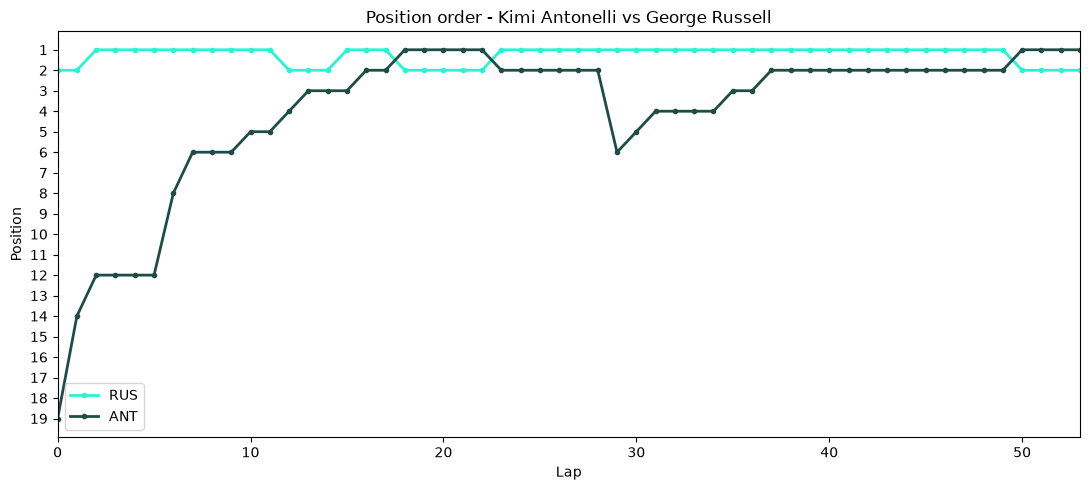

In [14]:
grid_positions = session_mz.results.set_index("Abbreviation")["GridPosition"]

position_by_driver = {
    code: mz_laps.pick_drivers(code)[["LapNumber", "Position"]].dropna().sort_values("LapNumber")
    for code in merc_drivers
}

fig, ax = plt.subplots(figsize=(11, 5))

line_styles = {"RUS": "-", "ANT": "-"}
line_colors = {"RUS": "#27F4D2", "ANT": "#1E4D45"}

for code in merc_drivers:
    d = position_by_driver[code]
    laps = pd.concat([pd.Series([0]), d["LapNumber"]])
    positions = pd.concat([pd.Series([grid_positions[code]]), d["Position"]])
    ax.plot(laps, positions, line_styles[code], color=line_colors[code],
            linewidth=2, marker="o", markersize=3, label=code)

ax.invert_yaxis()
ax.yaxis.set_major_locator(plt.MultipleLocator(1))
ax.set_xlabel("Lap")
ax.set_ylabel("Position")
ax.set_title(f"Position order - Kimi Antonelli vs George Russell")
ax.set_xlim(0, mz_total_laps)
ax.legend()
plt.tight_layout()
plt.show()

As we can see Kimi jumped 5 places from P19 to P14 in the first lap showing how good Kimi is. He very quickly made his way up the field and jumping up to P5 in just 10 laps. Sheer talent (and a rocketship). 

By around lap 17 he has already caught up to Russell and overtakes him on lap 18 and they battle it out till lap 28 when Kimi comes into the pits to put on a new set of Mediums tyres.

He comes out of the pits in P6 (but others still need to pit), then with pace of the new tyres catches back up to Russell and overtakes him on lap 49 to eventually become the first Italian in 60 years to win the Italian Grand Prix at the age of 19. Crazy

Lets focus more on Kimis final stint on the Mediums to see how much faster he actually was and how much pacing Russell was dropping on them old hard tyres.

## Final stint pace: Kimis fresh Mediums vs Russells slow old Hards

Lets look at how far behind Russell Kimi was when he comes out the pits with his new Mediums and look how the gap between the two decreases lap by lap and when he eventually overtakes Russell.

In [40]:
gap_laps = mz_laps.pick_drivers(merc_drivers)[["Driver", "LapNumber", "Time"]].dropna()
gap = gap_laps.pivot(index="LapNumber", columns="Driver", values="Time")
gap["GapToRUS"] = (gap["ANT"] - gap["RUS"]).dt.total_seconds()
print(gap.loc[29:][["GapToRUS"]].to_string())

overtake_lap = int(gap.loc[29:][gap.loc[29:]["GapToRUS"] < 0].index.min())

Driver     GapToRUS
LapNumber          
29.0         14.288
30.0         13.223
31.0         12.470
32.0         11.802
33.0         11.374
34.0         10.631
35.0          9.756
36.0          9.217
37.0          8.343
38.0          7.817
39.0          7.524
40.0          7.043
41.0          6.289
42.0          5.499
43.0          4.716
44.0          3.932
45.0          2.786
46.0          1.686
47.0          0.953
48.0          0.249
49.0          0.856
50.0         -1.226
51.0         -1.218
52.0         -1.890
53.0         -3.872


Kimi comes out the pits about 14 seconds behind Russell and passes him at lap 50 as shown by the negative gap.
Lets look at how much faster Kimi was than Russell when he was chasing him from lap 30 to 48

In [16]:
chase_laps = mz_laps.pick_drivers(merc_drivers)
chase_laps = chase_laps[(chase_laps["LapNumber"] >= 30) & (chase_laps["LapNumber"] <= 48)]
chase_avg = chase_laps.groupby("Driver")["LapTime"].mean().dt.total_seconds()

print(f"Antonelli was on average {chase_avg['RUS'] - chase_avg['ANT']:.3f}s/lap faster than Russell during the chase")

Antonelli was on average 0.739s/lap faster than Russell during the chase


0.739s in the F1 world is a LOT.

Now we need to see how much Russells pace dropped during that period

In [38]:
rus_30_48 = mz_laps.pick_drivers("RUS")
rus_30_48 = rus_30_48[(rus_30_48["LapNumber"] >= 30) & (rus_30_48["LapNumber"] <= 48)][["LapNumber", "LapTime"]].copy()
rus_30_48["LapTimeSec"] = rus_30_48["LapTime"].dt.total_seconds()
print(rus_30_48[["LapNumber", "LapTimeSec"]].to_string(index=False))

x = rus_30_48["LapNumber"]
y = rus_30_48["LapTimeSec"]
slope = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean()) ** 2).sum()
print(f"\nAverage pace drop: {slope:+.3f}s per lap over laps 30-48")

 LapNumber  LapTimeSec
      30.0      85.660
      31.0      85.569
      32.0      85.340
      33.0      85.404
      34.0      85.412
      35.0      85.296
      36.0      85.223
      37.0      85.337
      38.0      85.386
      39.0      85.018
      40.0      85.094
      41.0      85.331
      42.0      85.137
      43.0      85.261
      44.0      85.128
      45.0      85.183
      46.0      84.961
      47.0      84.861
      48.0      85.276

Average pace drop: -0.027s per lap over laps 30-48


Russells tyre degradation doesnt seem to be as much as expected but Kimis new Mediums were much more overpowering than the drop off in pace from Russell.

Lets look at a graph that shows the tyre degradation/pace change between the two drivers from lap 30 until the chequered flag.

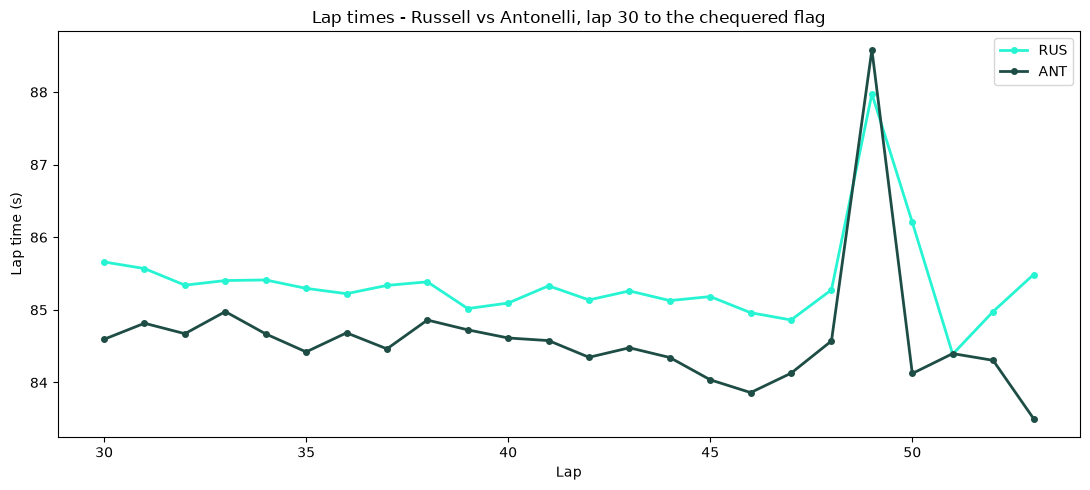

In [ ]:
pace_laps = mz_laps.pick_drivers(merc_drivers)
pace_laps = pace_laps[pace_laps["LapNumber"] >= 30]

fig, ax = plt.subplots(figsize=(11, 5))
for code in merc_drivers:
    d = pace_laps.pick_drivers(code)
    ax.plot(d["LapNumber"], d["LapTime"].dt.total_seconds(), color=line_colors[code],
            linewidth=2, marker="o", markersize=4, label=code)

ax.set_xlabel("Lap")
ax.set_ylabel("Lap time (s)")
ax.set_title("Lap times - Russell vs Antonelli, lap 30 to the end")
ax.legend()
plt.tight_layout()
plt.show()

From the graph we can clearly see the pace difference between the two. While Kimi was chasing, he was doing 84s while Russell was doing low 85s.
There is a spike at lap 49 because that was when they went wheel to wheel and Kimi actuall went off into the gravel at the first chicane losing him a bit of time.
Kimi then clawed back and his pace was too much to match for Russell and won the race.

## Summary of this race analysis

As you can see from the studied race above, race strategy is absolutely fundamental to a successful race. It was worth it from Kimi to box on lap 29 and lose about 15 seconds in the pitlane knowing the fresh set of Mediums will have the pace to reel Russell in.

The main takeaway from this race? Dont trust 50 lap Hard tyres will carry you to the end and it is clear Toto Wolff (Mercedes Team Principal) prioritises Kimi over Russell.

Russell shouldve pitted around 5 laps after Kimi pitted to try an overcut and come out with fresher tyres with a 5 lap tyre offset which should boost his chances of winning.

Our project would find out exactly what Russell shouldve done given Kimi pitted at lap 29 using ML :)